In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()
df_test = off_market.copy()

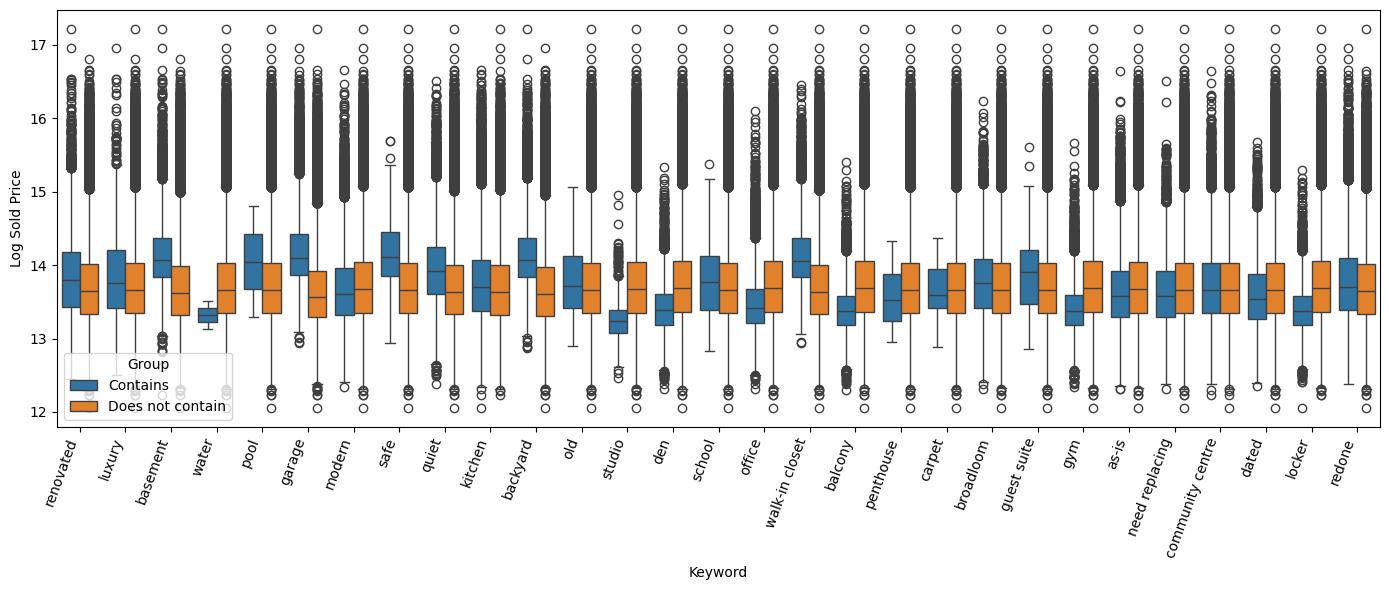

In [22]:
keywords = [
    "renovated", "luxury", "basement", "water",
    "pool", "garage", "modern", "safe", "quiet",
    "kitchen", "backyard", "old", "studio", "den",
    "school", "office", "walk-in closet", "balcony",
    "penthouse", "carpet", "broadloom", "guest suite",
    "gym", "as-is", "need replacing", "community centre",
    "dated", "locker", "redone"
]

df["log_sold_price"] = np.log(df["sold_price"])

plot_data = []
for word in keywords:
    mask = df["remarks"].str.contains(r"\b" + word + r"\b", case=False, na=False, regex=True)
    plot_data.extend([
        {"Keyword": word, "Group": "Contains", "Price": p}
        for p in df.loc[mask, "log_sold_price"]
    ])
    plot_data.extend([
        {"Keyword": word, "Group": "Does not contain", "Price": p}
        for p in df.loc[~mask, "log_sold_price"]
    ])

plot_df = pd.DataFrame(plot_data)

plt.figure(figsize=(14, 6))
sns.boxplot(data=plot_df, x="Keyword", y="Price", hue="Group")
plt.xticks(rotation=70, ha="right")
plt.ylabel("Log Sold Price")
plt.tight_layout()
plt.show()

In [20]:
for i in range(10):
    print(f"House Index: {df.index[i]}")
    print(f"Log Sold Price: {df['log_sold_price'].iloc[i]}")
    print(f"Remarks: {df['remarks'].iloc[i]}")
    print("\n")

House Index: 0
Log Sold Price: 12.805183834163525
Remarks: Looking For More Space In A Turnkey Condo? This 1-Bed, 1-Bath At Sumacpark Is Fully Redone With A Refreshed Bathroom And Newer Flooring. Unobstructed Views From Every Window. Nothing To Do But Unpack And Enjoy. Steps To Ravine Trails. A Smart Buy For Anyone Wanting Extra Room. Welcome Home.


House Index: 1
Log Sold Price: 13.303016877097587
Remarks: Imagine a quiet evening on Sequoia Trail, where this two-bedroom, one-bathroom condo offers a functional layout with good bones. Broadloom in the bedrooms adds comfort, and a locker provides extra storage for your belongings. The building includes guest suites, making it easy to host visitors. Parking is not included, but the library is close by for weekend outings. The finishes are original and will benefit from updates over time. This is a solid, liveable home for an investor looking for potential. The unit is offered as-is.


House Index: 2
Log Sold Price: 13.108061592693469
Rem